# Müşteri ayrılması: makine öğrenmesi

Ana soru: **Segment kuralından daha iyi bir öncelik sırası üretebilir miyiz?** Aynı kapasiteyle (ör. müşterilerin %20'si) ayrılanların daha büyük kısmını yakalamak hedeflenir. Model "kim ayrılacak" diye evet/hayır demez; her müşteriye bir risk skoru verip sıralar. Tarih olmadığı için "30 gün içinde" gibi bir iddia yoktur.

**Kararlar (2026-10-23, kullanıcı onayı):**
1. Veri ayrımı %70 eğitim / %15 geliştirme / %15 son test, sınıf oranı korunarak (`random_state=42`). Son test, model kararlarından sonra kullanıcı onayıyla 24 Ekim'de çalıştırıldı; mevcut sonuçlar tekrar model seçmek için kullanılmaz.
2. Ana ölçüt **Average Precision (AP)**; iş ölçütü **%10/20/30 kapasitede yakalanan ayrılan payı**; skorların olasılık olarak güvenilirliği için **Brier**. Accuracy kullanılmaz; eşik 0,5 otomatik değildir.
3. **"Aktif değil"** ayrılmanın belirtisi olabilir (sızıntı şüphesi): her model aktiflikli ve aktifliksiz eğitilir; Power BI'a aktifliksiz modelin skoru gider.
4. **Cinsiyet** modele girmez; grup performansı ayrıca raporlanır. Kimlik alanları (RowNumber, CustomerId, Surname) girdi değildir.
5. **İki hat:** A (ham değişkenler, Random Forest) ve B (EDA bilgili lojistik regresyon). Referanslar: Dummy ve eğitimde yeniden kurulan segment kuralı.
6. Dengesizlik için yeniden örneklemesiz, `class_weight="balanced"` ve SMOTENC karşılaştırılır; SMOTENC yalnızca eğitim katında uygulanır.
7. Son test ölçütlerine bootstrap güven aralığı eklenir.
8. **Eleştirel gözden geçirme sonrası (Bölüm 4b):** gradient boosting eklenir ve Optuna (Bayesçi optimizasyon, TPE) ile ayarlanır; Random Forest ve lojistik regresyon geniş rastgele aramayla yeniden ayarlanır; seçim tekrarlı CV ve "en iyiye 0,01 AP'den yakın en sade model" kuralıyla yapılır.

**Yöntem sınırı:** EDA tüm veride yapıldı; B hattının tasarım fikirleri (yaş eğrisi, ürün kategorisi, bakiye bayrağı, etkileşimler) test müşterilerini de içeren gözlemlerden geldi. Son test "ilk keşiften tamamen bağımsız" değildir. A hattında EDA'dan türetilmiş açık dönüşümler kullanılmaz; bu, RF'yi bütün keşif ve seçim sürecinden bağımsız yapmaz veya EDA'nın etkisini ölçmez.

**28 Ekim açıklama düzeltmesi:** Model/eğitim/seçim kodu ve kayıtlı çıktılar korunmuştur. Aşağıdaki yorumlarda değerlendirme sınırları ve eski kapasite hesabıyla güncel hesabın farkı doğrudan açıklanır; yeni eğitim veya model seçimi yapılmamıştır.


## 0. Kurulum

**Soru:** Doğru ortam ve doğru veri mi? Beklenen: Python 3.12.14, NumPy 2.2.6; 10.000 müşteri, 2.037 ayrılan.

In [1]:
from pathlib import Path
import platform, sys, warnings
import numpy as np
import pandas as pd
from IPython.display import display

working_dir = Path.cwd().resolve()
project_root = next(
    (f for f in (working_dir, *working_dir.parents) if (f / "Churn_Modelling.csv").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Proje klasörünü veya notebooks klasörünü açın.")
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from churn_analysis import eda, ml

print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| pandas:", pd.__version__)
eda.stil_uygula()
veri = eda.hazirla(pd.read_csv(project_root / "Churn_Modelling.csv"))
cikti = project_root / "reports" / "ml"
cikti.mkdir(parents=True, exist_ok=True)
print(f"Müşteri: {eda.tr_sayi(len(veri))} | Ayrılan: {eda.tr_sayi(veri['Exited'].sum())} | Oran: %{eda.tr_sayi(100 * veri['Exited'].mean(), 2)}")

def yuzde(t, kolonlar, basamak=1):
    """Tabloda 0-1 aralığındaki ölçütleri okunur yüzde metnine çevirir (yalnızca gösterim)."""
    t = t.copy()
    for k in kolonlar:
        t[k] = t[k].map(lambda v: f"%{eda.tr_sayi(100 * v, basamak)}")
    return t

Python: 3.12.14 | NumPy: 2.2.6 | pandas: 3.0.6
Müşteri: 10.000 | Ayrılan: 2.037 | Oran: %20,37


## 1. Veri ayrımı

**Soru:** Model nerede öğrenecek, nerede seçilecek, nerede ölçülecek?

**Yöntem ve gerekçe:** Sınıf oranı korunarak hedef %70 eğitim / %15 geliştirme / %15 test ayrımı kuruldu. Kayıtlı gerçek adetler **7.000 / 1.499 / 1.501**'dir; ilk ayırma kodundaki ondalık oran hesabı bu farkı üretir. Mevcut bölüm üyelikleri korunur. Eğitimde model ve CV aramaları; geliştirmede karşılaştırma ve kalibrasyon kararları; testte kararlar sabitlendikten sonraki ölçüm yapıldı.

`data/processed/ml_veri_bolumu.csv`, müşteri bölümünü CustomerId ile eşleştirmek için saklanır. Aynı kaynak sırası ve tohumla aynı ayrım hedeflenir; müşteri sırasının değişmesi veya yeni veri eklenmesi ayrıca kontrol gerektirir.

**Sınır:** İlk EDA bütün veride yapılmıştı. Bu ayrım, sonraki eğitim işlemlerini ayırır; önceki keşfin etkisini ortadan kaldırmaz. Beklenen ayrılma oranı her bölümde yaklaşık %20,4'tür.


In [2]:
bolum = ml.veri_ayir(veri)
ozet = ml.bolum_ozeti(veri, bolum)
display(ozet.round(2))

(project_root / "data" / "processed").mkdir(parents=True, exist_ok=True)
pd.DataFrame({"CustomerId": veri["CustomerId"], "Bölüm": bolum}).to_csv(
    project_root / "data" / "processed" / "ml_veri_bolumu.csv", index=False, encoding="utf-8-sig")
eda.tablo_kaydet(ozet, "01_bolum_ozeti.csv", cikti)

egitim, gelistirme = veri[bolum.eq("Eğitim")], veri[bolum.eq("Geliştirme")]

,Müşteri,Ayrılan,Ayrılma oranı (%),Müşterilerin payı (%)
Bölüm,,,,
Eğitim,7000,1426,20.37,70.00
Geliştirme,1499,305,20.35,14.99
Test,1501,306,20.39,15.01


**Gözlem:** Üç bölümün ayrılma oranı %20,35–20,39 arasında; bu kayıtlı ayrımda hedef oranı korunmuş görünüyor. Eğitim 7.000, geliştirme 1.499, test 1.501 müşteri ve testte 306 ayrılandır.

**İş anlamı:** Modeller aynı kayıtlı müşteriler üzerinde karşılaştırılabilir. Benzer hedef oranı, bölümlerin bütün özelliklerde aynı dağıldığını veya gelecekteki müşterileri temsil ettiğini kanıtlamaz.

**Sınır:** Son test 24 Ekim'de görüldü. Artık yeni bağımsız test sayılmaz ve yeni model/ayar seçimi için kullanılmaz. Bootstrap aralıkları da önceki bütün keşif ve seçim belirsizliğini kapsamaz.


## 2. Girdiler ve model hatları

**Soru:** Model hangi bilgiyle, hangi biçimde öğrenecek?

| Girdi | A hattı (Random Forest, ham girdiler) | B hattı (lojistik regresyon, EDA bilgili) |
|---|---|---|
| Yaş | Ham sayı | Spline (eğri; ters U için), ölçekli |
| Ürün sayısı | Ham sayı | Kategori: 1 / 2 / 3+ |
| Bakiye | Ham sayı | Ölçekli + "bakiye pozitif" bayrağı |
| Ülke | One-hot | One-hot |
| Kredi puanı, ilişki süresi, gelir, kredi kartı | Ham | Ölçekli / 0-1 |
| Aktiflik | Ham (aktiflikli sürümde) | "Aktif değil" + 40–49 ve 50–59 yaş etkileşimleri (aktiflikli sürümde) |
| Etkileşimler | Model kendisi bulur | 1 ürün × pozitif bakiye, 3+ ürün × pozitif bakiye (EDA 4d'de odds ölçeğinde korunanlar) |
| Cinsiyet, kimlik alanları | Yok | Yok |

**Yöntem ve gerekçe:** Bütün dönüşümler `Pipeline` içinde; ölçekleme, kodlama, spline düğümleri ve SMOTENC yalnızca eğitim katında öğrenilir (çapraz doğrulamada her katın kendi eğitim parçasında). Random Forest ölçeklemeye ihtiyaç duymaz ve doğrusal olmayan ilişkileri ham değişkenlerden kendisi öğrenir; lojistik regresyon doğrusal olduğu için bu çalışmada yaşın doğrusal olmayan biçimi spline ile temsil edilir; bu, kullanılabilecek tek dönüşüm değildir.

**Referanslar:** Dummy (herkese eğitimdeki oran; rastgele sıralama) ve segment kuralı (EDA Bölüm 5 prosedürü yalnızca eğitim verisinde yeniden kurulur; her müşteri segmentinin eğitimdeki oranını alır).

**Hiperparametreler:** Küçük ızgaralar (Random Forest: yaprakta en az 5/20/50 müşteri, bölmede değişken payı √p / %50; lojistik regresyon: C = 0,01–10) AP'ye göre çapraz doğrulamada seçilir. Bu ilk tur dar tutuldu; Bölüm 4b'de genişletildi.

**Sınır:** Ham girdiler kullanmak önceki tüm-veri EDA'sından bağımsız doğrulama sağlamaz. SMOTENC bu çalışmada denenmiş seçeneklerden biridir; başarısız olması diğer model hatlarını değiştirmeyi gerektirmez. Buradaki eğitim yöntemi korunmuştur.


## 3. Eğitim verisinde 5 katlı çapraz doğrulama

**Soru:** Eğitim verisinde model ve dengesizlik seçeneklerinin kayıtlı sıralama sonuçları nasıl farklılaşıyor?

**Yöntem:** 7.000 müşteri 5 kata bölünür; her yapılandırma dört katta öğrenilip kalan katta ölçülür. Tablo katların ortalaması ve standart sapmasını gösterir. Aynı CV sonuçlarıyla en iyi ayarı seçmek iyimserlik yaratabilir; büyüklüğü burada ölçülmüş değildir.

**Sınır:** Geliştirme seti eğitim dışında bir karşılaştırma sağlar; model/kalibrasyon kararında kullanıldığı için seçimden bağımsız nihai doğrulama değildir. Katların standart sapması modeller arası fark testi değildir.


,Aktiflik,Model,Dengesizlik,Seçilen ayar,AP,ROC AUC,Brier,%10 kapasitede yakalanan,%20 kapasitede yakalanan,%30 kapasitede yakalanan,AP ss,%20 kapasitede yakalanan ss
0,Var,Referans · Dummy,—,—,0.204,0.500,0.162,0.100,0.200,0.300,0.000,0.000
1,Var,Referans · Segment kuralı,—,—,0.479,0.771,0.130,0.307,0.469,0.617,0.025,0.023
2,Var,A · Random Forest,Yok,"max_features=sqrt, min_samples_leaf=5",0.681,0.852,0.106,0.400,0.607,0.727,0.017,0.013
3,Var,B · Lojistik regresyon,Yok,C=10.0,0.674,0.850,0.107,0.386,0.588,0.722,0.027,0.020
4,Var,A · Random Forest,Sınıf ağırlığı,"max_features=0.5, min_samples_leaf=5",0.673,0.852,0.131,0.399,0.603,0.730,0.018,0.020
5,Var,B · Lojistik regresyon,Sınıf ağırlığı,C=0.1,0.673,0.849,0.154,0.387,0.591,0.728,0.026,0.019
6,Var,A · Random Forest,SMOTENC,"max_features=0.5, min_samples_leaf=20",0.625,0.847,0.139,0.363,0.589,0.734,0.023,0.018
7,Var,B · Lojistik regresyon,SMOTENC,C=10.0,0.658,0.843,0.148,0.377,0.587,0.724,0.024,0.014
8,Yok,Referans · Dummy,—,—,0.204,0.500,0.162,0.100,0.200,0.300,0.000,0.000
9,Yok,Referans · Segment kuralı,—,—,0.430,0.746,0.134,0.280,0.456,0.563,0.023,0.025


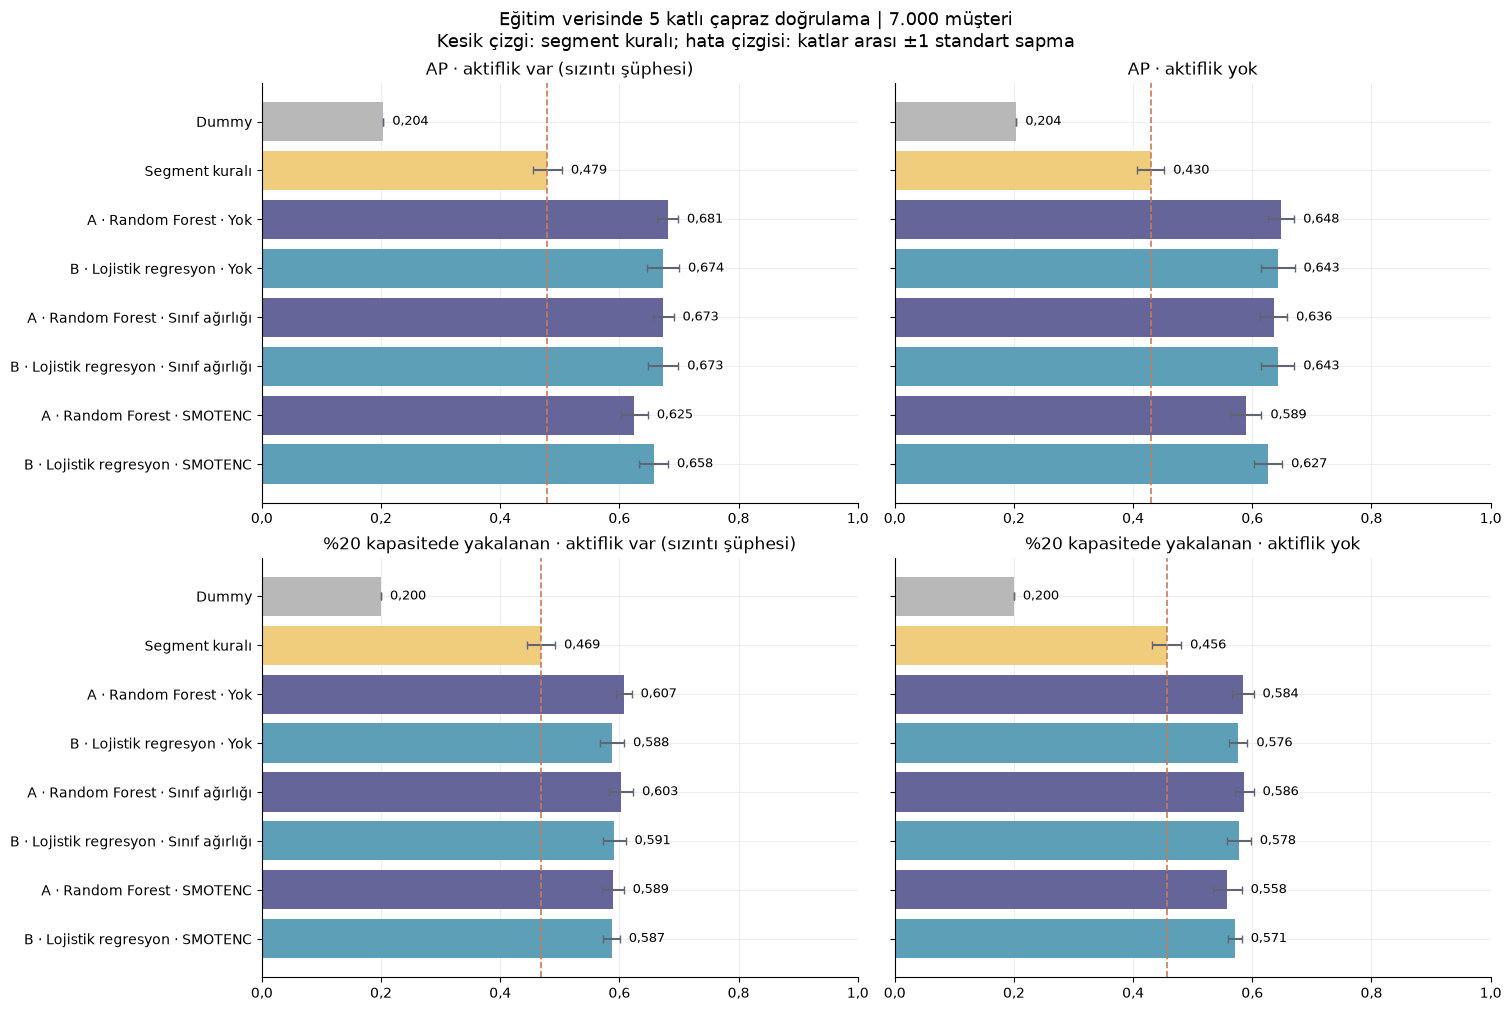

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    cv_tablo = ml.karsilastir(egitim)

olcut = ["AP", "ROC AUC", "Brier", "%10 kapasitede yakalanan", "%20 kapasitede yakalanan", "%30 kapasitede yakalanan"]
gorunum = cv_tablo[["Aktiflik", "Model", "Dengesizlik", "Seçilen ayar", *olcut, "AP ss", "%20 kapasitede yakalanan ss"]]
display(gorunum.round(3))
eda.tablo_kaydet(cv_tablo.drop(columns=["_dengesizlik", "_ayar"]), "03_cv_karsilastirma.csv", cikti, index=False)
ml.karsilastirma_grafigi(cv_tablo, "Eğitim verisinde 5 katlı çapraz doğrulama | 7.000 müşteri\n"
                         "Kesik çizgi: segment kuralı; hata çizgisi: katlar arası ±1 standart sapma",
                         cikti, "03_cv_karsilastirma.png")

**Gözlem:**
- Kayıtlı CV'de iyi yapılandırmaların AP'si yaklaşık 0,64–0,68; Dummy referansı yaklaşık 0,20'dir. %20 kapasitedeki eski hesapta ayrılanların yaklaşık %58–61'i yakalanıyor.
- RF ve lojistik regresyonun nokta sonuçları yakın. Bu tablo, EDA özelliklerinin LR'yi RF düzeyine taşıdığını tek başına kanıtlamaz; bunun için aynı ailede özellik katkısını ayrıca ayırmak gerekir.
- Bu adaylar ve arama kapsamı içinde sınıf ağırlığı/SMOTENC için daha iyi sıralama sonucu görülmedi; bazı seçeneklerin Brier'ı daha yüksek. Bu, dengesizlik yöntemlerinin genel olarak faydasız olduğu anlamına gelmez.
- Aktifliksiz sürümlerde AP yaklaşık 0,03, yakalama yaklaşık 2 puan daha düşük. Ölçüm zamanı bilinmediğinden bu fark üretimde kullanılabilecek katkı diye sunulmaz.
- Segment kuralının düşük CV sonucu, 5.600 kişilik eğitim katlarında bütün alt gruplar için n ≥ 100 koşulunun yaş bölünmesini durdurmasıyla ilişkilidir. Bu, yöntemin veri hacmine duyarlılığıdır; sonucu “adil değil” diye dışlamak doğru olmaz. Geliştirmede 7.000 müşteriyle kurulan kural farklı eğitim büyüklüğündeki sonucunu gösterir.

**İş anlamı:** Adayları araştırmak için işaretler var; kesin model üstünlüğü veya bağımsız başarı sonucu yok.

**Sınır:** Ayar seçimi ve ölçüm aynı CV'yi kullanır. Sonraki geliştirme karşılaştırması da seçim sürecinin bir parçasıdır. Tablonun kapasite değerleri ilk hesapla kaydedilmiştir; güncel tamsayı kuralı Bölüm 6 ve 8 yorumlarında açıklanır.


## 4. Geliştirme setinde karşılaştırma

**Soru:** Bütün eğitim verisinde (7.000) eğitilen yapılandırmalar, eğitimde kullanılmayan 1.499 geliştirme müşterisinde nasıl sıralıyor? Segment kuralı Power BI'daki hâline benzer biçimde 7.000 müşteride kurulur (22 segment).

**Bu turdaki yazılı seçim kuralı:** Her aktiflik sürümünde geliştirme AP'si en yüksek yapılandırma aday olur; fark 0,01'den küçükse Brier'ı daha iyi (skorları daha güvenilir) ve daha sade olan tercih edilir.

**Sınır:** Bu veri aday seçiminde kullanılır; seçilen yapılandırmanın bu tablodaki başarısı seçimden bağımsız doğrulama değildir. Brier'ın daha düşük olması da her müşteri grubunda kalibrasyon garantisi sağlamaz.


,Aktiflik,Model,Dengesizlik,AP,ROC AUC,Brier,%10 kapasitede yakalanan,%20 kapasitede yakalanan,%30 kapasitede yakalanan,%20 kapasitede isabet
0,Var,Referans · Dummy,—,0.203,0.500,0.162,"%10,0","%20,0","%30,0","%20,3"
1,Var,Referans · Segment kuralı,—,0.627,0.843,0.110,"%37,5","%57,7","%72,8","%58,7"
2,Var,A · Random Forest,Yok,0.710,0.872,0.101,"%40,3","%64,2","%76,1","%65,3"
3,Var,B · Lojistik regresyon,Yok,0.698,0.866,0.103,"%40,0","%60,3","%74,4","%61,4"
4,Var,A · Random Forest,Sınıf ağırlığı,0.701,0.871,0.126,"%39,6","%63,6","%76,1","%64,7"
5,Var,B · Lojistik regresyon,Sınıf ağırlığı,0.699,0.866,0.150,"%40,7","%61,9","%73,8","%63,0"
6,Var,A · Random Forest,SMOTENC,0.677,0.873,0.131,"%37,0","%62,0","%76,7","%63,0"
7,Var,B · Lojistik regresyon,SMOTENC,0.683,0.857,0.144,"%39,6","%60,6","%73,4","%61,6"
8,Yok,Referans · Dummy,—,0.203,0.500,0.162,"%10,0","%20,0","%30,0","%20,3"
9,Yok,Referans · Segment kuralı,—,0.591,0.834,0.114,"%35,7","%56,1","%70,9","%57,0"


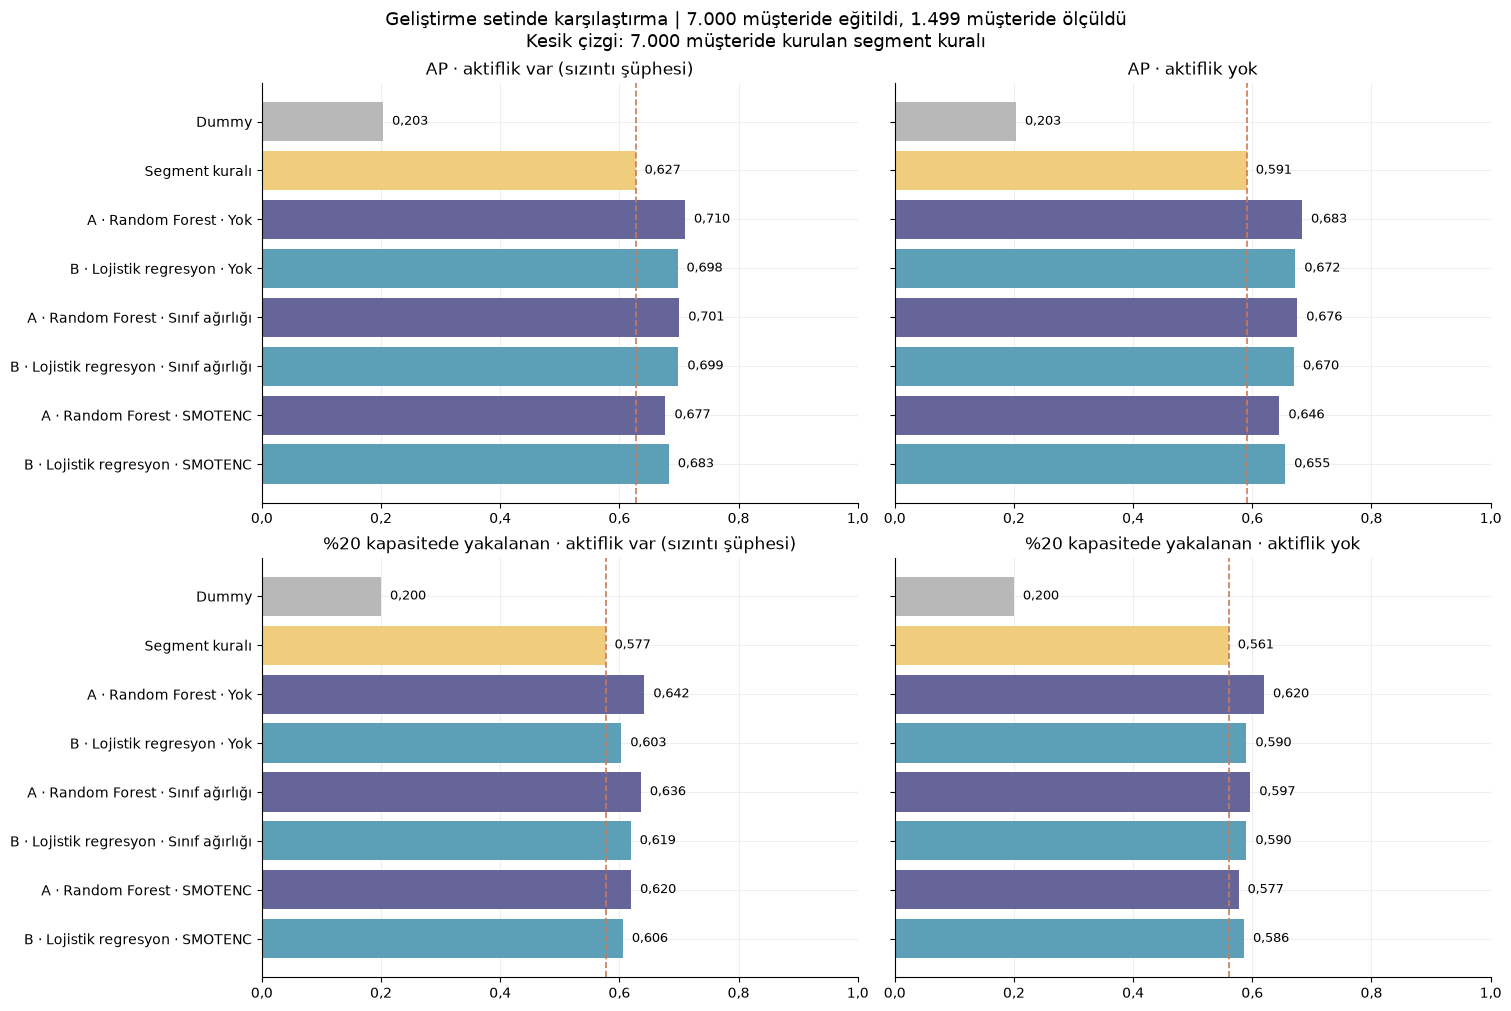

In [4]:
gel_tablo, gel_modeller = ml.gelistirme_degerlendir(egitim, gelistirme, cv_tablo)
display(yuzde(gel_tablo[["Aktiflik", "Model", "Dengesizlik", *olcut, "%20 kapasitede isabet"]].round(3),
              ["%10 kapasitede yakalanan", "%20 kapasitede yakalanan", "%30 kapasitede yakalanan", "%20 kapasitede isabet"]))
eda.tablo_kaydet(gel_tablo, "04_gelistirme_karsilastirma.csv", cikti, index=False)
ml.karsilastirma_grafigi(gel_tablo, "Geliştirme setinde karşılaştırma | 7.000 müşteride eğitildi, 1.499 müşteride ölçüldü\n"
                         "Kesik çizgi: 7.000 müşteride kurulan segment kuralı",
                         cikti, "04_gelistirme_karsilastirma.png")

**Gözlem:** İlk geliştirme turunda en yüksek AP, her iki aktiflik sürümünde de dengesizlik düzeltmesiz RF'de. Aktifliksiz AP 0,683 / eski %20 yakalama %62,0; aktiflikli AP 0,710 / %64,2. Aktifliksiz segment kuralı %56,1 yakalıyor. LR'nin AP farkı yaklaşık 0,01–0,03. Denenen ağırlık/SMOTENC seçenekleri bu turda tercih edilmedi.

**İş anlamı:** Bu karşılaştırma RF'yi sonraki arama için aday yaptı. Yaklaşık 6 puanlık geliştirme yakalama farkı, kampanyayla tutulacak ek müşteri sayısı değildir; testteki olay sayısıyla çarpılıp doğrulanmış bir iş kazancı gibi sunulmaz.

**Ara karar:** RF, düzeltmesiz ve aktifliksiz sürümle devam edildi; Bölüm 4b'de arama ve aile karşılaştırması genişletildi. Aktiflik ölçüm zamanı belirsizliğinden ötürü aktiflikli sonuç ayrıca raporlandı.

**Sınır:** Model seçimi geliştirme sonuçlarından yararlandı. Farkların ne kadarının seçim etkisi/örneklem değişkenliği olduğu bu karşılaştırmayla ayrılmaz. Son test ilk EDA'dan tamamen bağımsız değildir; bu sınır eski model sonuçlarını bütünüyle geçersiz kılmaz.


## 4b. Gradient boosting, geniş arama ve seçim kuralı

**Neden?** İlk turda gradient boosting denenmemiş ve RF/LR araması dar tutulmuştu. Ek aile ve daha geniş arama ile karşılaştırma kapsamı artırıldı; bu tek başına değerlendirmeyi bağımsız yapmaz.

**Yöntem ve gerekçe:**
- **Gradient boosting:** `HistGradientBoostingClassifier`, ham değişkenler ve erken durdurma. Sürekli parametrelerin de bulunduğu arama için Optuna'nın önceki denemelerden yararlanan TPE yöntemi kullanıldı; bütçe 50 denemeydi.
- **RF ve LR:** Sırasıyla ağaç ayarları ve C/spline düğümleri için 30'ar rastgele deneme. Sınıf ağırlığı arama seçeneklerindeydi. SMOTENC ilk tur sonuçları doğrultusunda bu turdan çıkarıldı; bu bir proje içi tercihtir, genel yöntem hükmü değildir.
- **Yazılı seçim kuralı:** Ailelerin seçilen ayarları farklı bölmelerle 5 kat × 3 tekrarlı CV'de ölçüldü. En yüksek AP'ye 0,01'den yakın adaylarda sadelik sırası LR → RF → GB uygulandı. 0,01 tolerans bakım/açıklama maliyeti için bir karar tercihidir; istatistiksel eşdeğerlik sınırı değildir.
- Tümü aktifliksiz girdilerle çalıştırıldı. Özgün Optuna/rastgele arama ve RF seçimi korunur.

**Sınır:** Bölmeler değişse de ayar araması ve tekrarlı CV aynı eğitim müşterilerini kullanır. Bu tekrar, ayar seçiminin yarattığı iyimserliği bütünüyle kaldırmaz; büyüklüğü ölçülmedi. Geliştirme seti de daha önce aday ve sonra kalibrasyon kararında kullanıldığından yalnız bağımsız doğrulama olarak tanımlanmaz.


In [5]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    arama_ozet, ayarlar, optuna_calisma = ml.genis_arama(egitim)
display(arama_ozet.round(4))
eda.tablo_kaydet(arama_ozet, "04b_genis_arama.csv", cikti, index=False)
optuna_calisma.trials_dataframe().to_csv(cikti / "04b_optuna_denemeleri.csv", index=False, encoding="utf-8-sig")

tekrarli = ml.tekrarli_cv(egitim, ayarlar)
display(tekrarli.round(4))
eda.tablo_kaydet(tekrarli, "04b_tekrarli_cv.csv", cikti, index=False)
secim = ml.sade_secim(tekrarli)
print(f"Seçim kuralına göre ana model: {secim} (en iyiye {ml.SECIM_TOLERANSI} AP'den yakın en sade model)")

X_egt0, X_gel0 = ml.girdiler(egitim, aktiflik=False), ml.girdiler(gelistirme, aktiflik=False)
y_egt, y_gel = egitim["Exited"].to_numpy(), gelistirme["Exited"].to_numpy()
dogrulama = pd.DataFrame([{"Model": ad, **ml.olcutler(y_gel, ml.aday_kur(ad, X_egt0, a).fit(X_egt0, y_egt).predict_proba(X_gel0)[:, 1])}
                          for ad, a in ayarlar.items()])
display(yuzde(dogrulama[["Model", *olcut]].round(4), ["%10 kapasitede yakalanan", "%20 kapasitede yakalanan", "%30 kapasitede yakalanan"]))
eda.tablo_kaydet(dogrulama, "04b_gelistirme_dogrulama.csv", cikti, index=False)

def kur(X):
    """Seçilen ailenin seçilen ayarla kurulmuş, eğitilmemiş modeli."""
    return ml.aday_kur(secim, X, ayarlar[secim])

C:\Users\goktu\Churn_analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Model,Arama,En iyi CV AP,AP ss,%20 kapasitede yakalanan,Denemelerin AP aralığı,Seçilen ayar
0,B · Lojistik regresyon,"Rastgele, 30 deneme",0.6429,0.0272,0.5764,0.513–0.643,"n_knots=5, C=0.689, class_weight=None"
1,A · Random Forest,"Rastgele, 30 deneme",0.6443,0.0230,0.5842,0.518–0.644,"class_weight=None, max_depth=15, max_features=..."
2,A · Gradient Boosting,"Optuna (TPE), 50 deneme",0.6554,0.0213,0.5835,0.640–0.655,"learning_rate=0.0141, max_leaf_nodes=19, min_s..."


,Model,AP,AP ss,%20 kapasitede yakalanan,%20 ss,Brier
0,B · Lojistik regresyon,0.6408,0.0295,0.5797,0.0205,0.1127
1,A · Random Forest,0.6429,0.0266,0.5767,0.0296,0.1124
2,A · Gradient Boosting,0.6516,0.0300,0.5832,0.0250,0.1111
3,Referans · Segment kuralı,0.4299,0.0201,0.4562,0.0198,0.1340


Seçim kuralına göre ana model: A · Random Forest (en iyiye 0.01 AP'den yakın en sade model)


,Model,AP,ROC AUC,Brier,%10 kapasitede yakalanan,%20 kapasitede yakalanan,%30 kapasitede yakalanan
0,B · Lojistik regresyon,0.6724,0.8556,0.1080,"%38,7","%59,3","%73,7"
1,A · Random Forest,0.6849,0.8648,0.1056,"%39,7","%61,3","%74,8"
2,A · Gradient Boosting,0.6885,0.8686,0.1046,"%39,7","%61,3","%75,1"


**Gözlem:** Tekrarlı CV'de AP ortalamaları GB 0,651632; RF 0,642910; LR 0,640782. Geliştirmede GB/RF AP 0,6885/0,6849; eski %20 yakalama hesabı ikisinde yaklaşık %61,3. Katlar arası ss yaklaşık 0,03'tür; bu değer farkların yalnız gürültü olduğunu kanıtlamaz.

**Karar:** Yazılı tolerans/sadelik kuralı RF'yi seçti. GB'ye farkı 0,008722 ile 0,01 içinde; LR'nin farkı 0,010850 ile dışarıda. Bu bir karar kuralının sonucudur; “RF kesinlikle en iyi” veya “aileler eşdeğer” sonucu değildir. Seçilen ayarlarda sınıf ağırlığı `None` kaldı; `balanced` denenmiş olması son modelde seçildiği anlamına gelmez.

**İş anlamı:** Karşılaştırılan adaylar ve yazılı tercih altında RF ile devam etmek gerekçelendirildi. Geniş aramada ayarların ilk tura yakın kalması ek gözlemdir; ilk seçimi bağımsız olarak doğrulamaz.

**Sınır:** Optuna'daki 50 denemenin AP aralığı 0,640–0,655. Bu, daha uzun aramanın kazanım sağlayamayacağını veya yalnızca CV'yi zorlayacağını göstermez. Aynı müşterilerde arama/tekrarlı CV seçim iyimserliğini koruyabilir; testteki başka model sonuçları RF'yi değiştirmek için kullanılmaz.


## 5. Kalibrasyon

**Soru:** Model bir müşteriye 0,60 dediğinde bu "yaklaşık %60 ihtimalle ayrılır" diye okunabilir mi? Sayfa 3'teki "listede yaklaşık X ayrılan beklenir" cümlesi buna bağlı.

**Yöntem ve gerekçe:** Bölüm 4b'de seçilen model üç biçimde karşılaştırılır: ham, Sigmoid (Platt) ve İzotonik kalibrasyon. Kalibrasyon eğitim verisinde 5 katlı `CalibratedClassifierCV` ile öğrenilir; ölçüm geliştirme setindedir. Güvenilirlik grafiği skorları 10 eşit büyüklükte dilime ayırır ve her dilimde ortalama skor ile gerçek ayrılma oranını karşılaştırır; noktaların köşegene yakınlığı bu geliştirme örnekleminde kalibrasyonu destekler; her grupta veya yeni veride güvenilirlik garantisi değildir.

**Seçim ölçütü:** Brier ve en riskli dilimlerde beklenen ile gerçek ayrılan uyumu; AP'nin korunması.

**Sınır:** Kalibrasyon seçeneklerini karşılaştırıp seçmek geliştirme verisini kullanır; aynı verideki sonuç bağımsız nihai başarı değildir. Skorlar belirli bir gelecek dönem veya teklif yanıtı olasılığı olarak yorumlanmaz.


,Kalibrasyon,Brier,AP,%20 kapasitede yakalanan,Ortalama skor,Gerçek oran
0,Ham,0.1056,0.6849,0.6125,0.2054,0.2035
1,Sigmoid,0.1052,0.6833,0.6164,0.2066,0.2035
2,İzotonik,0.1047,0.6828,0.6098,0.2063,0.2035


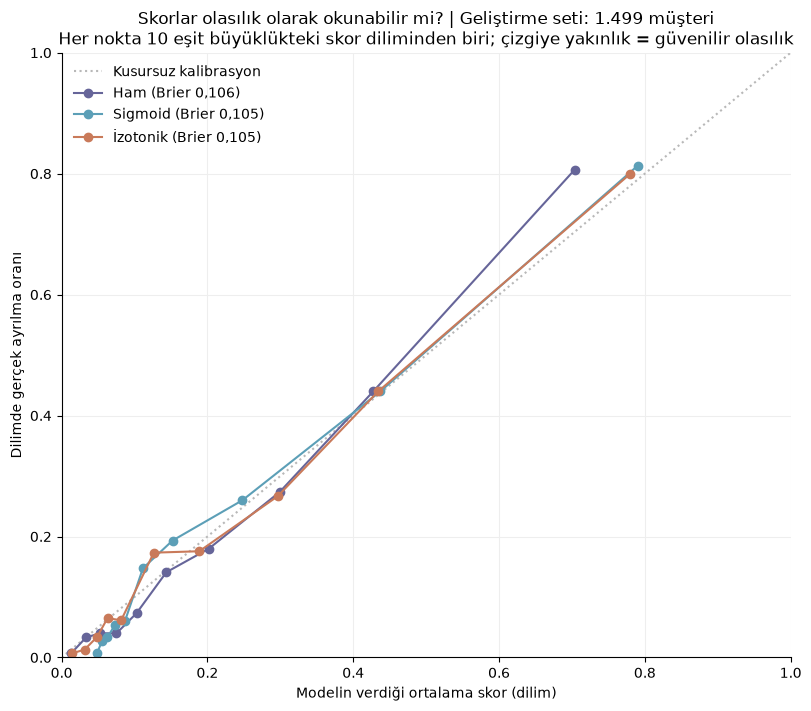

Ham


,Kapasite,Bakılan müşteri,Skor eşiği,Beklenen ayrılan (skor toplamı),Gerçek ayrılan,Yakalanan pay,İsabet
0,%10,150,0.565,105.574,121,0.397,0.807
1,%20,300,0.344,169.699,187,0.613,0.623
2,%30,450,0.248,214.532,228,0.748,0.507


Sigmoid


,Kapasite,Bakılan müşteri,Skor eşiği,Beklenen ayrılan (skor toplamı),Gerçek ayrılan,Yakalanan pay,İsabet
0,%10,150,0.646,118.554,122,0.400,0.813
1,%20,300,0.308,184.134,188,0.616,0.627
2,%30,450,0.190,221.334,227,0.744,0.504


İzotonik


,Kapasite,Bakılan müşteri,Skor eşiği,Beklenen ayrılan (skor toplamı),Gerçek ayrılan,Yakalanan pay,İsabet
0,%10,150,0.643,117.040,120,0.393,0.800
1,%20,300,0.354,182.188,186,0.610,0.620
2,%30,450,0.242,226.644,226,0.741,0.502


In [6]:
kal_tablo, kal_skorlar = ml.kalibrasyon_karsilastir(egitim, gelistirme, model_kur=kur)
y_gel = gelistirme["Exited"].to_numpy()
display(kal_tablo.round(4))
eda.tablo_kaydet(kal_tablo, "05_kalibrasyon.csv", cikti, index=False)
ml.kalibrasyon_grafigi(y_gel, kal_skorlar, cikti, "05_kalibrasyon.png")
for k in ml.KALIBRASYONLAR:
    print(k)
    display(ml.kapasite_tablosu(y_gel, kal_skorlar[k]).round(3))

**Gözlem:** Ham modelin en üst geliştirme diliminde ortalama skor yaklaşık 0,70, gerçek ayrılma oranı yaklaşık %81. İlk 150 kişilik eski listede ham skor toplamı 106, gerçek ayrılan 121; Sigmoid'de yaklaşık 119/122, İzotonik'te 117/120. Liste üyeleri yöntemler arasında aynı olmak zorunda değildir.

Sigmoid ve İzotonik'te bu üst dilim uyumu daha yakın. Genel Brier 0,1047–0,1056, AP 0,683–0,685; en düşük genel Brier İzotonik'tedir. Bu farklar için burada ayrı belirsizlik hesabı yok.

**Karar:** Üst kapasite dilimindeki uyum ve AP'nin korunması birlikte değerlendirilerek Sigmoid seçildi. Bu seçim son testten önce yapıldı; test sonucuyla kalibrasyon seçilmez veya değiştirilmez. Özgün karar korunur.

**Sınır:** Birkaç dilimde skor toplamının gözlenen sayıya yaklaşması bütün modelin kalibrasyonunu kanıtlamaz. Geliştirme örneklemi 1.499; grafik dilimleri yaklaşık 150 müşteri. Gösterilen kapasite tabloları ilk hesapla kaydedilmiştir.


## 6. Kapasite listeleri ve eşikler

**Soru:** Tutma ekibi %10, %20 veya %30 kapasiteyle çalışırsa kaç müşteriye bakar, kaç ayrılan bulur?

**Yöntem:** Önerilen (Sigmoid) skorlarla geliştirme setinde müşteriler sıralanır; her kapasite için liste büyüklüğü, skor eşiği, beklenen (skorların toplamı) ve gerçek ayrılan sayısı. Kapasite, sabit bir skor eşiği değil liste büyüklüğü olarak tanımlanır; Power BI'da da böyle kullanılacak.

**Kapasite düzeltmesi:** Güncel kural `floor(n × kapasite / 100)` ile kapasite aşılmaz; eşit skorlar somut listede CustomerId ile çözülür. Aşağıdaki tablo eski çalışmanın çıktısıdır: 1.499 kişide yuvarlama %20 için 300 seçmişti; güncel kural 299 seçer. Bu tablo yeniden hesaplanmadı; eski sayıların güncel kuralla üretildiği iddia edilmez. Model eğitimi değiştirilmez.


In [7]:
kapasite = ml.kapasite_tablosu(y_gel, kal_skorlar["Sigmoid"])
display(yuzde(kapasite.round(3), ["Yakalanan pay", "İsabet"]))
eda.tablo_kaydet(kapasite, "06_kapasite_gelistirme.csv", cikti, index=False)

,Kapasite,Bakılan müşteri,Skor eşiği,Beklenen ayrılan (skor toplamı),Gerçek ayrılan,Yakalanan pay,İsabet
0,%10,150,0.646,118.554,122,"%40,0","%81,3"
1,%20,300,0.308,184.134,188,"%61,6","%62,7"
2,%30,450,0.190,221.334,227,"%74,4","%50,4"


**Gözlem — kayıtlı geliştirme tablosu:** Eski %20 listesinde 300 müşteri / 188 ayrılan; yakalama %61,6 ve isabet %62,7. Eski %10 listesinde 150 müşteri / 122 ayrılan; yakalama %40,0 ve isabet %81,3.

**İş anlamı:** Bu kayıtlı sonuçlarda daha dar liste daha yüksek isabetle, daha düşük toplam yakalamayı birlikte getiriyor. Uygun kapasite iş kararıdır; teklifin gerçek etkisi bu sayılardan çıkmaz.

**Sınır:** Bunlar 1.499 geliştirme müşterisinin eski yuvarlama hesabıdır. Güncel tamsayı kapasitede %10/%20/%30 adetleri 149/299/449'dur; o listelerin yakalama sayısı burada yeniden üretilmedi. Testteki 1.501 müşterinin %20 listesi ise eski ve güncel hesapta 300'dür; Bölüm 8'de ayrı açıklanır.


## 7. Model neye dayanıyor? (permutation importance)

**Soru:** Model sıralamayı hangi bilgiyle yapıyor?

**Yöntem ve gerekçe:** Geliştirme setinde her değişken tek tek rastgele karıştırılır (20 tekrar) ve AP'nin ne kadar düştüğüne bakılır. Büyük düşüş = model bu bilgiye çok dayanıyor. Ağaç modellerinin yerleşik önem ölçüsü yerine bu yöntem seçildi; çok değerli sayısal değişkenleri kayırma eğilimi daha azdır.

**Sınır:** Önem, nedensellik değildir; "ürün sayısını değiştirirsek müşteri kalır" anlamına gelmez.

In [8]:
aday = ml.kalibre(kur(X_egt0), "Sigmoid").fit(X_egt0, egitim["Exited"])
onem = ml.onem_tablosu(aday, X_gel0, y_gel)
display(onem.round(4))
eda.tablo_kaydet(onem, "07_permutation_onem.csv", cikti, index=False)

,Değişken,AP düşüşü,ss
0,Ürün sayısı,0.2768,0.0246
1,Yaş,0.2437,0.0191
2,Ülke,0.0803,0.0122
3,Bakiye,0.0526,0.0087
4,Tahmini gelir,0.0050,0.0028
5,Banka ile ilişki süresi,0.0015,0.0013
6,Kredi kartı,0.0003,0.0003
7,Kredi puanı,-0.0033,0.0026


**Gözlem:** Geliştirme setinde değişkenleri karıştırınca en büyük AP düşüşü ürün sayısı ve yaşta; ardından ülke ve bakiyede. Diğer alanların bu ölçümdeki önem tahmini sıfıra yakın.

**İş anlamı:** Model sıralamasının bu örneklemde hangi alanlara daha duyarlı olduğu görülüyor. EDA'daki örüntülerle uyum, ayrı ve bağımsız bir doğrulama değildir; sıfıra yakın önem de değişkenin her durumda bilgisiz olduğunu göstermez.

**Sınır:** Bağlantılı değişkenler birbirinin bilgisini taşıyabilir; karıştırma önemi model/örnekleme koşulludur. Nedensellik, müşteriyi tutma etkisi veya özellik seçimi kararı çıkarılmaz.


## 7b. Testten önce tanı kontrolleri

**Soru:** Model bazı müşteri gruplarını sistematik olarak kaçırıyor mu, kimleri kaçırıyor, sonuç rastgeleliğe ve aşırı öğrenmeye karşı sağlam mı?

**Neden testten önce?** Bu kontroller yalnızca testte yapılsaydı, bir sorun çıktığında düzeltme şansı kalmazdı. Geliştirme setinde ve eğitim verisinde yapılır; **bu tanı adımında test kullanılmaz.** İlk tüm-veri keşfinin sınırı yine geçerlidir.

**Kural (sonuçlara bakmadan önce yazıldı):** Bu kontroller yalnızca tanı ve raporlama içindir; model, ayar ve kalibrasyon bunlara göre değiştirilmez. Yeni bir değişiklik önerisi ayrı bir geliştirme kararı gerektirir; bu tanı sonuçlarına bakılarak burada uygulanmaz. Hata analizinden çıkan fikirler bu projede uygulanmaz, "gelecek çalışma" olarak kalır.

**Yöntem:**
1. **Grup performansı:** Geliştirme setinde tek bir genel liste (eski yuvarlamayla %20 = 300 müşteri; güncel aşağı yuvarlama 299); her grupta ayrılanların ne kadarı listeye girdi? Cinsiyet modele girmediği hâlde dolaylı fark oluşabilir.
2. **Hata analizi:** Listeye giren (yakalanan) ve girmeyen (kaçırılan) ayrılanların profili.
3. **Kararlılık:** Aynı ayar, 5 farklı rastgele tohum; ve eğitim katlarındaki skor ile görülmemiş katlardaki (CV) skorun farkı (aşırı öğrenme göstergesi).

**Sınır:** Beş model tohumu aynı sabit geliştirme bölümünde karşılaştırılır; bu yeni veri/bölüm kararlılığı değildir. Eğitim–CV farkı tanısaldır; tek başına aşırı uyumun boyutunu veya kabul edilebilirliğini belirlemez.


In [9]:
s_gel = aday.predict_proba(X_gel0)[:, 1]
grup_gel = ml.grup_performansi(y_gel, s_gel, ml.gruplar(gelistirme))
display(yuzde(grup_gel.round(3), ["Ayrılma oranı", "Listeye giren müşteri payı", "Yakalanan ayrılan payı"]))
eda.tablo_kaydet(grup_gel, "07b_grup_performansi_gelistirme.csv", cikti, index=False)

profil, profil_ozet = ml.kacirilan_profili(gelistirme, y_gel, s_gel)
print(profil_ozet)
display(profil.round(1))
eda.tablo_kaydet(profil, "07b_kacirilan_profili.csv", cikti, index=False)

kararli = ml.kararlilik(egitim, gelistirme, kur)
display(kararli.round(4))
fark = ml.ogrenme_farki(egitim, kur)
display(fark.round(4))
eda.tablo_kaydet(kararli, "07b_tohum_kararliligi.csv", cikti, index=False)
eda.tablo_kaydet(fark, "07b_egitim_cv_farki.csv", cikti, index=False)

,Değişken,Grup,Müşteri,Ayrılan,Ayrılma oranı,Listeye giren müşteri payı,Yakalanan ayrılan payı,Not
0,Cinsiyet,Kadın,716,187,"%26,1","%21,6","%61,0",
1,Cinsiyet,Erkek,783,118,"%15,1","%18,5","%62,7",
2,Ülke,Fransa,747,116,"%15,5","%14,1","%56,0",
3,Ülke,İspanya,368,65,"%17,7","%13,3","%50,8",
4,Ülke,Almanya,384,124,"%32,3","%38,0","%72,6",
5,Yaş grubu,18–39,906,83,"%9,2","%2,8","%18,1",
6,Yaş grubu,50–59,122,66,"%54,1","%77,0","%93,9",
7,Yaş grubu,40–49,398,133,"%33,4","%38,9","%72,2",
8,Yaş grubu,60–69,53,21,"%39,6","%45,3","%71,4",n < 100 · temkinli
9,Yaş grubu,70+,20,2,"%10,0","%10,0","%0,0",n < 100 · temkinli


{'Yakalanan ayrılan': 188, 'Kaçırılan ayrılan': 117}


,Değişken,Yakalanan ayrılanlar (medyan),Kaçırılan ayrılanlar (medyan),Kalan müşteriler (medyan)
0,Yaş,48.0,38.0,36.0
1,Ürün sayısı,1.0,1.0,2.0
2,Bakiye,109557.5,110148.5,91315.8
3,Kredi puanı,663.5,656.0,649.0
4,Banka ile ilişki süresi,5.0,5.0,5.0
5,Tahmini gelir,108370.2,94554.7,103841.0


,Tohum,AP,%20 kapasitede yakalanan,Brier
0,0,0.6846,0.6131,0.1052
1,1,0.6837,0.6131,0.1053
2,2,0.6836,0.6131,0.1051
3,3,0.6853,0.6164,0.1050
4,4,0.6846,0.6164,0.1051


,Ölçüt,Eğitim katları,Doğrulama katları (CV)
0,AP,0.7245,0.6443
1,%20 kapasitede yakalanan,0.6403,0.5842
2,Brier,0.0996,0.1121


**Gözlem — kayıtlı geliştirme listesi:**
- Kadın ayrılanların %61,0'ı, erkeklerin %62,7'si listede. Nokta oranları yakın; bu eşit performans kanıtı değildir. Grupların listeye alınma paylarının farklı olması yalnız taban oranına bağlanamaz.
- Yakalama Almanya'da %72,6, Fransa'da %56,0, İspanya'da %50,8. 18–39 yaşta 83 ayrılandan 15'i (%18,1), 2 ürünlü ayrılanların %25,5'i listede.
- Kaçırılan 117 ayrılanın medyan yaşı 38, yakalananlarınki 48. Bu profil farkı, kaçırılmanın nedenini veya başka bir kampanyanın işe yarayacağını kanıtlamaz.
- Beş tohumda AP 0,6836–0,6853; eski %20 yakalama %61,3–61,6. Bu sınırlı denemede tohuma duyarlılık küçük; sonuçların genel olarak rastgelelikten bağımsız olduğu söylenmez.
- Eğitim katı AP 0,7245, doğrulama katı AP 0,6443. Fark bir genelleme uyarısıdır; “beklenen/orta düzeyde, dolayısıyla sorun yok” sonucu verilmez.

**İş anlamı:** Genel yüksek risk listesi bazı gruplardaki ayrılanları az kapsıyor. Düşük grup taban riski bu durumla uyumlu olabilir; kapasite ve model etkileri burada ayrıştırılmadı. Genç müşteri kaybını azaltma amacı için listenin yeterliliği ayrıca değerlendirilmelidir; başka sinyal veya teklifin çözüm olacağı varsayılmaz.

**Karar:** Bu tanılar raporlandı; yazılı tanı kapsamı gereği model/ayar/kalibrasyon değiştirilmedi. Bu, bütün gruplarda sorun bulunmadığı anlamına gelmez.

**Sınır:** Eski 300 kişilik geliştirme listesi korunmuş çıktıdır. 60–69 yaşta n=53, 70+'da n=20 ve yalnız 2 ayrılan; 3+ ürünlülerde n=41. Küçük müşteri sayısı ve az olay ayrı belirsizlik kaynaklarıdır; oranlar tek başına kesin hüküm için yeterli değildir.


## 8. Son test (tek sefer)

**Durum: kullanıcı onayladı ve test 2026-10-24'te bir kez çalıştırıldı.** Özgün kodda `SON_TEST_ONAYI` açık kalmıştır; bu kayıtlı sonuçları incelemek için hücreyi veya Run All'ı tekrar çalıştırmak gerekmez. Yeniden çalıştırma yeni bağımsız test üretmez ve bu yorum düzenlemesinde yapılmamıştır.

**Testten önce sabitlenen protokol:**

| Madde | Karar |
|---|---|
| Ana model | Bölüm 4b'nin seçtiği **A · Random Forest** (geniş aramanın ayarıyla), dengesizlik düzeltmesiz, **aktifliksiz**, **Sigmoid** kalibrasyon |
| Eğitim | Eğitim + geliştirme birleştirilip (8.499 müşteri) yeniden eğitilir; ayarlar değişmez |
| Karşılaştırılanlar | Segment kuralı (aktifliksiz ve aktiflikli), A · gradient boosting ve B · lojistik regresyon (aktifliksiz, Bölüm 4b ayarlarıyla, Sigmoid), ana modelin aktiflikli sürümü (aynı ayar, Sigmoid), Dummy; hepsi aynı 8.499 müşteride kurulur |
| Ölçütler | AP; %10/20/30 kapasitede yakalanan; %20'de isabet; Brier; 2.000 tekrarlı eşleştirilmiş bootstrap ile %95 güven aralığı ve segment kuralına (aktifliksiz) göre fark |
| Grup performansı | %20 kapasitede tek genel liste; cinsiyet, ülke ve yaş gruplarında yakalanan ayrılan payı |
| Çıktı | Test setindeki 1.501 müşterinin skoru, sırası ve kapasite dilimi → `data/processed/ml_test_skorlari.csv` (SQL 29, Power BI Sayfa 3) |

**Kural:** Test sonucu görüldükten sonra model, ayar, kalibrasyon veya eşik değiştirilmez. Kod hatası bulunursa düzeltilir ve raporda açıkça yazılır.

**Hesap sürümü:** Aşağıdaki tablolar ve bootstrap aralıkları 24 Ekim çalışmasının korunmuş çıktılarıdır. Güncel kapasite kuralı ve kayıtlı skor denetiminin farkları sonraki yorumda belirtilir; bu tablolar yeniden çalıştırılmış değildir. Test ilk tüm-veri EDA'sından tamamen bağımsız değildir.


In [10]:
SON_TEST_ONAYI = True  # 2026-10-24: kullanıcı onayladı ("son testi onaylıyorum"); test seti bir kez açıldı.

if not SON_TEST_ONAYI:
    print("Son test henüz onaylanmadı; bu hücre test setine dokunmadı.")
else:
    test = veri[bolum.eq("Test")]
    egitim_gel = veri[bolum.isin(["Eğitim", "Geliştirme"])]
    y_eg, y_test = egitim_gel["Exited"].to_numpy(), test["Exited"].to_numpy()
    X0_eg, X0_test = ml.girdiler(egitim_gel, False), ml.girdiler(test, False)
    X1_eg, X1_test = ml.girdiler(egitim_gel, True), ml.girdiler(test, True)
    yontemler = {
        f"{secim.split(' · ')[1]} · aktifliksiz (ana model)": (ml.kalibre(kur(X0_eg), "Sigmoid"), X0_eg, X0_test),
        "Segment kuralı · aktifliksiz": (ml.SegmentKurali(), X0_eg, X0_test),
        **{f"{ad.split(' · ')[1]} · aktifliksiz": (ml.kalibre(ml.aday_kur(ad, X0_eg, a), "Sigmoid"), X0_eg, X0_test)
           for ad, a in ayarlar.items() if ad != secim},
        f"{secim.split(' · ')[1]} · aktiflikli": (ml.kalibre(kur(X1_eg), "Sigmoid"), X1_eg, X1_test),
        "Segment kuralı · aktiflikli": (ml.SegmentKurali(), X1_eg, X1_test),
        "Dummy": (ml.dummy(), X0_eg, X0_test),
    }
    test_modeller, test_skorlar = {}, {}
    for ad, (model, Xa, Xt) in yontemler.items():
        test_modeller[ad] = model.fit(Xa, y_eg)
        test_skorlar[ad] = model.predict_proba(Xt)[:, 1]
    test_tablo = pd.DataFrame([{"Yöntem": ad, **ml.olcutler(y_test, s)} for ad, s in test_skorlar.items()])
    display(yuzde(test_tablo[["Yöntem", *olcut, "%20 kapasitede isabet"]].round(3),
                  ["%10 kapasitede yakalanan", "%20 kapasitede yakalanan", "%30 kapasitede yakalanan", "%20 kapasitede isabet"]))
    eda.tablo_kaydet(test_tablo, "08_son_test.csv", cikti, index=False)

    bootstrap = ml.bootstrap_araliklari(y_test, test_skorlar, referans="Segment kuralı · aktifliksiz")
    display(bootstrap.round(3))
    eda.tablo_kaydet(bootstrap, "08_son_test_bootstrap.csv", cikti, index=False)

,Yöntem,AP,ROC AUC,Brier,%10 kapasitede yakalanan,%20 kapasitede yakalanan,%30 kapasitede yakalanan,%20 kapasitede isabet
0,Random Forest · aktifliksiz (ana model),0.675,0.857,0.106,"%38,9","%61,1","%73,9","%62,3"
1,Segment kuralı · aktifliksiz,0.589,0.838,0.113,"%35,6","%58,7","%72,5","%59,9"
2,Lojistik regresyon · aktifliksiz,0.682,0.852,0.106,"%38,3","%60,1","%74,5","%61,3"
3,Gradient Boosting · aktifliksiz,0.685,0.861,0.104,"%39,5","%61,4","%75,2","%62,6"
4,Random Forest · aktiflikli,0.726,0.872,0.099,"%42,5","%62,7","%76,5","%64,0"
5,Segment kuralı · aktiflikli,0.624,0.850,0.109,"%38,0","%61,8","%72,0","%63,0"
6,Dummy,0.204,0.500,0.162,"%10,0","%20,0","%30,0","%20,4"


,Yöntem,AP,AP GA alt,AP GA üst,AP farkı (Segment kuralı · aktifliksiz),AP farkı GA alt,AP farkı GA üst,%20 kapasitede yakalanan,%20 kapasitede yakalanan GA alt,%20 kapasitede yakalanan GA üst,%20 kapasitede yakalanan farkı (Segment kuralı · aktifliksiz),%20 kapasitede yakalanan farkı GA alt,%20 kapasitede yakalanan farkı GA üst
0,Random Forest · aktifliksiz (ana model),0.675,0.625,0.727,0.086,0.054,0.114,0.611,0.565,0.656,0.024,-0.008,0.053
1,Segment kuralı · aktifliksiz,0.589,0.535,0.646,NaN,NaN,NaN,0.587,0.546,0.631,NaN,NaN,NaN
2,Lojistik regresyon · aktifliksiz,0.682,0.632,0.733,0.093,0.064,0.122,0.601,0.557,0.649,0.014,-0.011,0.041
3,Gradient Boosting · aktifliksiz,0.685,0.636,0.736,0.097,0.067,0.125,0.614,0.569,0.662,0.027,-0.003,0.058
4,Random Forest · aktiflikli,0.726,0.681,0.772,0.137,0.101,0.172,0.627,0.581,0.673,0.040,0.005,0.074
5,Segment kuralı · aktiflikli,0.624,0.568,0.681,0.036,0.017,0.053,0.618,0.568,0.659,0.031,0.004,0.047
6,Dummy,0.204,0.185,0.225,-0.385,-0.438,-0.336,0.200,0.200,0.200,-0.387,-0.431,-0.346


**Gözlem — 24 Ekim testinin korunmuş sonuçları:**
- Ana model AP 0,675 (eski %95 bootstrap aralığı 0,625–0,727); %20 yakalama %61,1 (eski aralık %56,5–65,6). Geliştirmedeki AP 0,683 / yakalama %61,6'ya yakınlık görülüyor; bu, seçim sürecinde aşırı uyum olmadığını kanıtlamaz.
- En yüksek skorlu 300 kişide skor toplamı yaklaşık 187, tarihsel etikette ayrılan 187. İlk 150'de yaklaşık 121/119. Bu listelerdeki uyum kalibrasyonu destekleyen sınırlı gözlemdir; bütün dilimlerde/gruplarda veya yeni veride güvenilirlik garantisi değildir.
- Eski eşleştirilmiş bootstrap'ta RF–segment AP farkı +0,086 (0,054…0,114), %20 yakalama farkı +2,4 puan (−0,8…+5,3). Genel sıralama farkı ile tek kapasitedeki fark ayrı sorulardır. %20 için sıfır fark aralığın içinde; bu kapasitede üstünlük veya eşdeğerlik kanıtı kurulmaz.
- GB (AP 0,685) ve LR (0,682) nokta sonuçları da tabloda. Güven aralıklarının örtüşmesi eşdeğerliği veya RF seçim kuralının doğrulandığını göstermez. Bu sonuçlarla ana model değiştirilmez.
- Aktiflikli RF'de AP 0,726, %20 yakalama %62,7. Ölçüm zamanı bilinmediğinden bu “ulaşılabilir üretim başarısı” diye sunulmaz.

**Güncel kapasite açıklaması:** Kayıtlı 1.501 müşteri / 306 ayrılan üzerinde `floor(n × kapasite / 100)` ile %20 liste yine 300 kişi ve 187 ayrılandır: yakalama %61,11, isabet %62,33. Eski kesirli paydayla isabet %62,292 idi. Segmentin eşit skorlarda beklenen yakalaması 179,765'ten 179,697'ye düzeldi; bu kesirli beklenti 300 kişilik bir seçim içindir. Somut liste eşitlikte CustomerId ile seçilir, `Exited` kullanılmaz; skor toplamı bunlardan ayrı bir olasılık beklentisidir. %50 kapasite 750 müşteridir; test bölümü 1.500'e değiştirilmemiştir.

**Kayıtlı skorlarla güncel belirsizlik denetimi:** RF ve segmentin altı ondalıklı CSV skorlarında daha önce ayrı hesaplanan 2.000 eşleştirilmiş bootstrap'ta %20 yakalama farkı +2,39 puan, aralığı −0,77…+5,20 puandır. AP farkı +0,0859, aralığı +0,0550…+0,1165. Bunlar yukarıdaki eski tabloların yeniden üretimi veya diğer beş yöntemin güncellemesi değildir.

**İş anlamı:** Bu veride 300 kişilik liste 306 ayrılandan 187'sini kapsıyor; aynı adetli rastgele listenin beklenen yakalaması yaklaşık 61. Bu, gerçekten aranmış veya teklifle tutulmuş müşteri sayısı değildir. RF bireysel skorla esnek sıralama sağlar; segment kuralı daha şeffaf bir karşılaştırmadır. Buradan doğrudan uygulama veya kesin kampanya kazancı sonucu çıkarılmaz.

**Sınır:** Bootstrap sabit skorlara koşulludur; bütün eğitim/ayar seçimi ve ilk tüm-veri keşfinin belirsizliğini kapsamaz. CSV hassasiyeti de küçük fark yaratabilir. Kampanya başarı oranı, maliyet ve müşteri değeri senaryo varsayımıdır; istatistiksel ilişki, sıralama başarısı ve teklif etkisi ayrı değerlendirilir.


## 9. Grup performansı ve skor çıktısı

**Soru:** Model bazı müşteri gruplarını sistematik olarak gözden kaçırıyor mu? Cinsiyet modele girmedi; ama dolaylı yoldan (ör. yaş, ülke) farklı yakalama oranları oluşabilir.

**Yöntem:** Test setinde ana modelin skoruyla tek bir genel liste kurulur (en riskli %20). Her grupta "ayrılanların ne kadarı listeye girdi" ölçülür. 100'den küçük gruplar ve 30'dan az ayrılanı olan gruplar temkinli işaretlenir.

**Skor çıktısı:** Test setindeki 1.501 müşteri için CustomerId, ana model skoru, sıra, kapasite dilimi ve karşılaştırma için segment kuralının skoru. Eğitim ve geliştirme müşterilerinin skorları dışa aktarılmaz; bunlar bağımsız tahmin sayılmaz.

**Hesap/yorum sınırı:** Aşağıdaki tablo ilk çalışmanın kayıtlı çıktısıdır; yeni sayılar/aralıklar eklenmiş gibi sunulmaz. Güncel ayrı grup kontrolü ve yerel panel aynı sabit test listesinde yakalanan/ayrılan sayılarını ve %95 Wilson aralıklarını gösterir. Bu aralıklar betimseldir; tam model seçimi belirsizliğini veya grup eşitliğini kanıtlamaz.


In [11]:
if not SON_TEST_ONAYI:
    print("Son test henüz onaylanmadı; grup performansı ve skor çıktısı üretilmedi.")
else:
    ana = test_skorlar[f"{secim.split(' · ')[1]} · aktifliksiz (ana model)"]
    yas = pd.cut(test["Age"], [0, 40, 50, 60, 70, np.inf], right=False,
                 labels=["18–39", "40–49", "50–59", "60–69", "70+"]).astype(str)
    gruplar = {"Cinsiyet": test["Gender"].map({"Female": "Kadın", "Male": "Erkek"}),
               "Ülke": test["Geography"].map({"France": "Fransa", "Germany": "Almanya", "Spain": "İspanya"}),
               "Yaş grubu": yas}
    grup = ml.grup_performansi(y_test, ana, gruplar)
    display(yuzde(grup.round(3), ["Ayrılma oranı", "Listeye giren müşteri payı", "Yakalanan ayrılan payı"]))
    eda.tablo_kaydet(grup, "09_grup_performansi.csv", cikti, index=False)

    sira = pd.Series(ana).rank(ascending=False, method="first").astype(int).to_numpy()
    dilim = pd.cut(sira / len(sira) * 100, [0, 10, 20, 30, 100], labels=["İlk %10", "%10–20", "%20–30", "Diğer"])
    skor_cikti = pd.DataFrame({
        "CustomerId": test["CustomerId"].to_numpy(), "Bölüm": "Test",
        "Model skoru": ana.round(6), "Sıra": sira, "Kapasite dilimi": dilim.astype(str),
        "Segment kuralı skoru": test_skorlar["Segment kuralı · aktifliksiz"].round(6),
        "Model sürümü": "RF aktifliksiz Sigmoid · 8.499 müşteride eğitildi · 2026-10",
    }).sort_values("Sıra")
    skor_cikti.to_csv(project_root / "data" / "processed" / "ml_test_skorlari.csv", index=False, encoding="utf-8-sig")
    display(skor_cikti.head(10))
    print(f"Yazılan müşteri: {len(skor_cikti)} | İlk %20'de: {(sira <= round(0.2 * len(sira))).sum()}")

,Değişken,Grup,Müşteri,Ayrılan,Ayrılma oranı,Listeye giren müşteri payı,Yakalanan ayrılan payı,Not
0,Cinsiyet,Kadın,693,167,"%24,1","%21,6","%61,1",
1,Cinsiyet,Erkek,808,139,"%17,2","%18,6","%61,2",
2,Ülke,İspanya,352,57,"%16,2","%12,2","%49,1",
3,Ülke,Fransa,778,134,"%17,2","%14,9","%51,5",
4,Ülke,Almanya,371,115,"%31,0","%38,0","%78,3",
5,Yaş grubu,40–49,390,125,"%32,1","%36,7","%72,8",
6,Yaş grubu,18–39,906,79,"%8,7","%3,5","%20,3",
7,Yaş grubu,50–59,134,79,"%59,0","%71,6","%83,5",
8,Yaş grubu,60–69,55,21,"%38,2","%49,1","%66,7",n < 100 · temkinli
9,Yaş grubu,70+,16,2,"%12,5","%12,5","%0,0",n < 100 · temkinli


,CustomerId,Bölüm,Model skoru,Sıra,Kapasite dilimi,Segment kuralı skoru,Model sürümü
82,15775318,Test,0.951502,1,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
1256,15655082,Test,0.951318,2,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
1114,15647898,Test,0.950882,3,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
800,15663410,Test,0.950658,4,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
174,15592583,Test,0.947978,5,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
446,15655123,Test,0.942650,6,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
938,15589017,Test,0.942171,7,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
274,15610446,Test,0.942071,8,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
288,15779176,Test,0.940330,9,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...
1037,15569249,Test,0.939258,10,İlk %10,0.863309,RF aktifliksiz Sigmoid · 8.499 müşteride eğiti...


Yazılan müşteri: 1501 | İlk %20'de: 300


**Gözlem:** Kadın ayrılanların 102/167'si (%61,1), erkeklerin 85/139'u (%61,2) listede. Nokta oranları yakın; “cinsiyette fark yok” veya model adildir sonucu çıkarılmaz. Cinsiyeti girdiden çıkarmak dolaylı grup farklarını engellemez.

Ülke yakalaması Almanya %78,3; Fransa %51,5; İspanya %49,1. 18–39 yaşta 79 ayrılandan 16'sı (%20,3), 40–49'da %72,8 ve 50–59'da %83,5 listede. Genç gruptaki düşük kapsama geliştirme örneklemindeki gözlemle aynı yöndedir; bu, nedenini doğrulamaz.

**İş anlamı:** Genel %20 listesi genç ayrılanların çoğunu ve Almanya dışındaki ayrılanların yaklaşık yarısını dışarıda bırakıyor. Bu sınır karar verene gösterilir. Başka sinyal veya kampanya araştırılabilir; etkili olacağı mevcut analizle kanıtlanmış değildir.

**Belirsizlik:** 60–69 yaş n=55 / 21 ayrılan; 70+ n=16 / 2 ayrılan. 70+ için 0/2 yakalamanın %95 Wilson aralığı yaklaşık %0–65,8'dir; %0 tek başına kesin başarısızlık oranı değildir. Müşteri sayısının azlığı ve ayrılan olayın azlığı ayrı belirtilir. Yeni aralıklar eski tabloya yazılmadı; yorum ve yerel panelde görünürdür.

**Skor çıktısı:** 1.501 test müşterisi ve ilk %20'de 300 kişi korunur. SQL 29 ve ilk Power BI aktarımı daha önce tamamlandı; bu yorum düzenlemesinde CSV, SQL veya PBIX değiştirilmedi.


## 10. Güncel durum ve sıradaki adımlar

1. Son test 24 Ekim'de yapıldı; özgün RF/Optuna/kalibrasyon akışı korunuyor. Yeni model denemesi geri alındı; bu açıklama düzenlemesinde model eğitilmedi veya seçilmedi.
2. SQL skor aktarımı ve dört sayfalık ilk Power BI paneli tamamlandı. Yerel kapasite ve grup belirsizliği düzenlemeleri korunur; Service yerel son düzeltmelerden önceki sürümdür.
3. 28 Ekim'de yalnız Markdown yorumları düzeltildi. Kodlar, kayıtlı tablolar/grafikler ve skorlar korunur. Eski kapasite tabloları ile güncel hesap farkları ilgili bölümlerde açıklanır.
4. Bu yorumları ve önce/sonra günlüğünü birlikte değerlendireceğiz. Panelin görünür metin kontrolü, deney tasarımı/simülasyon ve teslim işleri henüz tamamlanmış sayılmaz. Kampanya senaryoları gerçek etki sonucu değildir.

Kullanıcıyla tartışmadan commit/push yapılmaz. Bu adım için notebook'u yeniden çalıştırmak gerekmez.
